 Imports libraries, loads the dataset, and defines features and disease labels.

In [1]:
import os, json, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score, precision_score,
                             hamming_loss, accuracy_score, roc_curve, multilabel_confusion_matrix)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

DATA_DIR = r"C:\Users\minsa_\Downloads"
OUT_DIR = os.path.join(DATA_DIR, "results_numbers_only")
os.makedirs(OUT_DIR, exist_ok=True)
RANDOM_STATE = 42
LABEL_COLS = ["FECD", "Guttata", "Folds", "PolyPleo", "LowCD"]
FEATURES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]

df = pd.read_csv(os.path.join(DATA_DIR, "Final_Features_MultiLabel_updated.csv"))
train = df[df["Split"] == "train"].reset_index(drop=True)
test  = df[df["Split"] == "test"].reset_index(drop=True)
X_tr, Y_tr, g_tr = train[FEATURES], train[LABEL_COLS].values, train["Donor_Group"]
X_te, Y_te       = test[FEATURES],  test[LABEL_COLS].values

print("Train:", X_tr.shape, "| Test:", X_te.shape)
pd.DataFrame({"Train": Y_tr.sum(0), "Test": Y_te.sum(0)}, index=LABEL_COLS)

Train: (1238, 6) | Test: (310, 6)


,Train,Test
FECD,115,29
Guttata,158,39
Folds,621,155
PolyPleo,294,70
LowCD,317,76


Creates five-fold grouped cross-validation and defines preprocessing pipelines and machine learning models.

In [2]:
strat_key = train["FECD"] * 4 + train["Guttata"] * 2 + train["Folds"]      # keeps diseases balanced across folds
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
             .split(train, strat_key, groups=g_tr))
fold_id = np.zeros(len(train), int)
for k, (_, va) in enumerate(folds):
    fold_id[va] = k
display(pd.DataFrame(Y_tr, columns=LABEL_COLS).groupby(fold_id).sum().rename_axis("Fold"))

def pipe(model, scale):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("sc", StandardScaler()))
    return Pipeline(steps + [("m", model)])

MODELS = {
    "Logistic Regression": (pipe(LogisticRegression(class_weight="balanced", max_iter=5000), True),
                            {"m__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                  random_state=RANDOM_STATE, n_jobs=-1), False),
                      {"m__max_depth": [3, 5, None], "m__min_samples_leaf": [1, 5, 10]}),
    "Gradient Boosting": (pipe(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE), False),
                          {"m__learning_rate": [0.03, 0.1], "m__max_depth": [2, 3], "m__min_samples_leaf": [10, 30]}),
}

,FECD,Guttata,Folds,PolyPleo,LowCD
Fold,,,,,
0,24,31,124,59,74
1,24,31,124,59,55
2,22,32,124,56,66
3,22,32,124,62,60
4,23,32,125,58,62


Trains three models for each disease, tunes their hyperparameters, and compares their ROC-AUC performance.

In [3]:
oof = {name: np.zeros(Y_tr.shape) for name in MODELS}
best_params = {name: {} for name in MODELS}

for name, (base, grid) in MODELS.items():
    for j, lab in enumerate(LABEL_COLS):
        gs = GridSearchCV(base, grid, scoring="roc_auc", cv=folds, n_jobs=-1).fit(X_tr, Y_tr[:, j])
        best_params[name][lab] = gs.best_params_
        for tr, va in folds:
            m = gs.best_estimator_.fit(X_tr.iloc[tr], Y_tr[tr, j])
            oof[name][va, j] = m.predict_proba(X_tr.iloc[va])[:, 1]
    print("done:", name)

auc_table = pd.DataFrame({name: [roc_auc_score(Y_tr[:, j], p[:, j]) for j in range(len(LABEL_COLS))]
                          for name, p in oof.items()}, index=LABEL_COLS)
auc_table.loc["Macro average"] = auc_table.mean()
print("Train CV ROC-AUC per disease (donor-grouped 5-fold)")
auc_table.round(3)

done: Logistic Regression
done: Random Forest
done: Gradient Boosting
Train CV ROC-AUC per disease (donor-grouped 5-fold)


,Logistic Regression,Random Forest,Gradient Boosting
FECD,0.846,0.930,0.920
Guttata,0.528,0.540,0.527
Folds,0.640,0.653,0.657
PolyPleo,0.877,0.923,0.922
LowCD,0.989,0.990,0.988
Macro average,0.776,0.807,0.803


Selects the best model based on macro ROC-AUC and calculates disease-specific prediction thresholds.

In [4]:
BEST = auc_table.loc["Macro average"].idxmax()
P_oof = oof[BEST]
print("Best model (macro AUC):", BEST)

def youden_threshold(y, p):                     # threshold with best sensitivity + specificity
    fpr, tpr, thr = roc_curve(y, p)
    return float(np.clip(thr[np.argmax(tpr - fpr)], 0.01, 0.99))

THRESH = {lab: round(youden_threshold(Y_tr[:, j], P_oof[:, j]), 3) for j, lab in enumerate(LABEL_COLS)}
print("Per-disease thresholds (chosen on train CV):", THRESH)

def evaluate(Y, P, thr):
    T = np.array([thr[l] for l in LABEL_COLS])
    pred = (P >= T).astype(int)
    rows = {}
    for j, lab in enumerate(LABEL_COLS):
        y, p, yhat = Y[:, j], P[:, j], pred[:, j]
        rows[lab] = {"n_pos": int(y.sum()), "ROC_AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
                     "F1": f1_score(y, yhat, zero_division=0),
                     "Sensitivity": recall_score(y, yhat, zero_division=0),
                     "Specificity": recall_score(y, yhat, pos_label=0, zero_division=0),
                     "Precision": precision_score(y, yhat, zero_division=0)}
    per = pd.DataFrame(rows).T
    normal_true = (Y.sum(1) == 0).astype(int)
    normal_pred = (pred.sum(1) == 0).astype(int)
    overall = {"Macro ROC-AUC": per["ROC_AUC"].mean(),
               "Macro F1": f1_score(Y, pred, average="macro", zero_division=0),
               "Micro F1": f1_score(Y, pred, average="micro", zero_division=0),
               "Hamming loss": hamming_loss(Y, pred),
               "Exact match": accuracy_score(Y, pred),
               "Normal-vs-disease AUC": roc_auc_score(1 - normal_true, P.max(1)),
               "Normal detected (specificity)": recall_score(normal_true, normal_pred, zero_division=0)}
    return per, pd.Series(overall), pred

per_cv, overall_cv, _ = evaluate(Y_tr, P_oof, THRESH)
print(f"TRAIN CV - {BEST}")
display(per_cv.round(3))
overall_cv.round(3).to_frame("Train CV")

Best model (macro AUC): Random Forest
Per-disease thresholds (chosen on train CV): {'FECD': 0.324, 'Guttata': 0.167, 'Folds': 0.498, 'PolyPleo': 0.477, 'LowCD': 0.291}
TRAIN CV - Random Forest


,n_pos,ROC_AUC,PR_AUC,F1,Sensitivity,Specificity,Precision
FECD,115.0,0.930,0.536,0.477,0.957,0.790,0.318
Guttata,158.0,0.540,0.150,0.222,0.361,0.723,0.160
Folds,621.0,0.653,0.634,0.577,0.527,0.700,0.639
PolyPleo,294.0,0.923,0.807,0.756,0.765,0.919,0.748
LowCD,317.0,0.990,0.949,0.938,0.981,0.962,0.899


,Train CV
Macro ROC-AUC,0.807
Macro F1,0.594
Micro F1,0.612
Hamming loss,0.211
Exact match,0.313
Normal-vs-disease AUC,0.754
Normal detected (specificity),0.577


Trains the final models, predicts the five diseases on unseen test data, and calculates evaluation metrics and confidence intervals.

In [5]:
models_final = []
P_te = np.zeros(Y_te.shape)
for j, lab in enumerate(LABEL_COLS):
    m = MODELS[BEST][0].set_params(**best_params[BEST][lab]).fit(X_tr, Y_tr[:, j])
    models_final.append(m)
    P_te[:, j] = m.predict_proba(X_te)[:, 1]

per_te, overall_te, pred_te = evaluate(Y_te, P_te, THRESH)
print(f"HELD-OUT TEST - {BEST}")
display(per_te.round(3))
display(pd.concat([overall_cv, overall_te], axis=1, keys=["Train CV", "Test"]).round(3))

rng = np.random.default_rng(RANDOM_STATE)
ci = {}
for j, lab in enumerate(LABEL_COLS):
    s = []
    for _ in range(1000):
        i = rng.integers(0, len(Y_te), len(Y_te))
        if Y_te[i, j].min() != Y_te[i, j].max():
            s.append(roc_auc_score(Y_te[i, j], P_te[i, j]))
    ci[lab] = f"{per_te.loc[lab, 'ROC_AUC']:.3f} [{np.percentile(s, 2.5):.3f}, {np.percentile(s, 97.5):.3f}]"
print("Test ROC-AUC with 95% bootstrap CI:")
pd.Series(ci).to_frame("Test ROC-AUC [95% CI]")

HELD-OUT TEST - Random Forest


,n_pos,ROC_AUC,PR_AUC,F1,Sensitivity,Specificity,Precision
FECD,29.0,0.931,0.593,0.500,1.000,0.794,0.333
Guttata,39.0,0.457,0.111,0.100,0.154,0.723,0.074
Folds,155.0,0.629,0.622,0.536,0.452,0.768,0.660
PolyPleo,70.0,0.928,0.860,0.739,0.729,0.929,0.750
LowCD,76.0,0.984,0.897,0.920,0.987,0.949,0.862


,Train CV,Test
Macro ROC-AUC,0.807,0.786
Macro F1,0.594,0.559
Micro F1,0.612,0.579
Hamming loss,0.211,0.217
Exact match,0.313,0.290
Normal-vs-disease AUC,0.754,0.746
Normal detected (specificity),0.577,0.654


Test ROC-AUC with 95% bootstrap CI:


,Test ROC-AUC [95% CI]
FECD,"0.931 [0.896, 0.959]"
Guttata,"0.457 [0.377, 0.542]"
Folds,"0.629 [0.569, 0.691]"
PolyPleo,"0.928 [0.895, 0.958]"
LowCD,"0.984 [0.969, 0.996]"


Plots ROC curves and confusion matrices to visualize disease prediction performance.

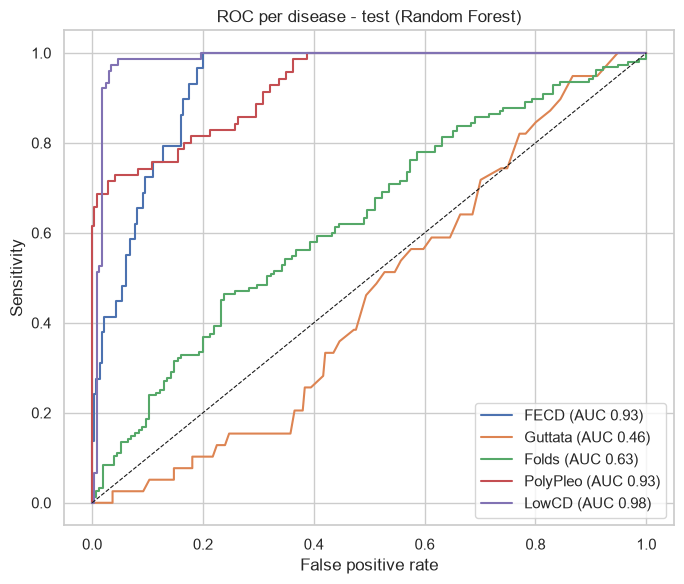

,True pos,Missed (FN),False alarm (FP),True neg
FECD,29,0,58,223
Guttata,6,33,75,196
Folds,70,85,36,119
PolyPleo,51,19,17,223
LowCD,75,1,12,222


In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
for j, lab in enumerate(LABEL_COLS):
    fpr, tpr, _ = roc_curve(Y_te[:, j], P_te[:, j])
    ax.plot(fpr, tpr, label=f"{lab} (AUC {per_te.loc[lab, 'ROC_AUC']:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set(xlabel="False positive rate", ylabel="Sensitivity", title=f"ROC per disease - test ({BEST})")
ax.legend(); plt.tight_layout(); plt.show()

mcm = multilabel_confusion_matrix(Y_te, pred_te)
pd.DataFrame([[c[1, 1], c[1, 0], c[0, 1], c[0, 0]] for c in mcm], index=LABEL_COLS,
             columns=["True pos", "Missed (FN)", "False alarm (FP)", "True neg"])

Compares actual and predicted disease combinations and calculates exact-match accuracy for each combination.

In [7]:
def combo(row):
    f = [l for l, v in zip(LABEL_COLS, row) if v]
    return " + ".join(f) if f else "Normal"

res = test[["Tissue_ID", "Combination"]].copy()
res["Predicted"] = [combo(r) for r in pred_te]
res["Exact_match"] = res["Combination"] == res["Predicted"]
print("Exact-match rate by true combination (test):")
res.groupby("Combination")["Exact_match"].agg(["size", "mean"]).round(2).sort_values("size", ascending=False)

Exact-match rate by true combination (test):


,size,mean
Combination,,
Normal,104,0.65
Folds,84,0.17
Folds + LowCD,21,0.00
FECD + PolyPleo + LowCD,18,0.28
Folds + PolyPleo + LowCD,15,0.00
Guttata,12,0.25
Guttata + Folds,11,0.00
Folds + PolyPleo,10,0.00
PolyPleo,6,0.00


Saves trained models, prediction probabilities, predicted labels, evaluation results, and related output files.

In [8]:
joblib.dump({"models": models_final, "labels": LABEL_COLS, "features": FEATURES, "thresholds": THRESH},
            os.path.join(OUT_DIR, "numbers_only_multilabel.joblib"))

out = test[["Tissue_ID", "Donor_Group"] + LABEL_COLS].copy()
for j, lab in enumerate(LABEL_COLS):
    out[f"P_{lab}"] = P_te[:, j]; out[f"Pred_{lab}"] = pred_te[:, j]
out.to_csv(os.path.join(OUT_DIR, "test_predictions_numbers_only.csv"), index=False)

oof_out = train[["Tissue_ID", "Donor_Group"] + LABEL_COLS].assign(Fold=fold_id)
for j, lab in enumerate(LABEL_COLS):
    oof_out[f"P_{lab}"] = P_oof[:, j]
oof_out.to_csv(os.path.join(OUT_DIR, "oof_predictions_numbers_only.csv"), index=False)

per_te.to_csv(os.path.join(OUT_DIR, "test_metrics_per_disease.csv"))
json.dump({"model": BEST, "features": FEATURES, "thresholds": THRESH,
           "best_params": {l: {k: str(v) for k, v in p.items()} for l, p in best_params[BEST].items()},
           "train_cv": overall_cv.round(4).to_dict(), "test": overall_te.round(4).to_dict()},
          open(os.path.join(OUT_DIR, "summary_numbers_only.json"), "w"), indent=2)
print("Saved to", OUT_DIR)

Saved to C:\Users\minsa_\Downloads\results_numbers_only
